# NumPy Applications in Python

## Solving Systems of Linear Equations

**Example:** Solve the following equations:

```
2x + y = 5

x + 3y = 10
```

## Write the equations as $A\mathbf{x}=\mathbf{b}$

$$
\begin{aligned}
2x+y&=5,\\
x+3y&=10.
\end{aligned}
$$

Each equation supplies one row of $A$. Keep the coefficients in the same order, first $x$ and then $y$. The vector $\mathbf{b}$ contains the right-hand sides in equation order. The unknown vector is $\mathbf{x}=(x,y)$. Each entry of $A\mathbf{x}$ is the dot product of one row of $A$ with $\mathbf{x}$.

**Predict.** The first dot product was 7. Does $(3,1)$ also satisfy the second equation?

Use **np.linalg.solve(A, b)** for this square system with a unique solution.

In [1]:
import numpy as np

# Coefficient matrix
l = [
        [2, 1],
        [1, 3]
]
A = np.array(l)

# Right-hand side vector
b = np.array([5, 10])

# Solve the system
solution = np.linalg.solve(A, b)
print("Solution [x, y]:", solution)

Solution [x, y]: [1. 3.]


## Use the residual to check your answer

The **residual** is $\mathbf{r}=A\mathbf{x}-\mathbf{b}$. A residual entry is the left-hand side minus the required right-hand side for that equation. 
- A positive entry means the left-hand side is too high. 
- A negative entry means it is too low.
- A correct numerical solution should give entries close to zero. 

The check below allows an absolute difference of $10^{-10}$ for this small example.

In [ ]:
residual = A @ solution - b

print("Computed left-hand sides:", A @ solution)
print("Residual:", residual)
print("Equations satisfied:", np.allclose(residual, 0, atol=1e-10, rtol=0))

### Solve following using numpy:

\begin{aligned}
2x + 3y - z + 4w &= 21\\
x - y + z &= 2\\
2y + z - w &= 3\\
x - z + 2w &= 6
\end{aligned}


In [2]:
# Answer:
import numpy as np

A = np.array([
    [2,  3, -1,  4],
    [1, -1,  1,  0],
    [0,  2,  1, -1],
    [1,  0, -1,  2],
])

b = np.array([21, 2, 3, 6])

solution = np.linalg.solve(A, b)
residual = A @ solution - b

print("Solution [x, y, z, w]", solution)        # [1. 2. 3. 4.]
print("Residual", residual)                     # Zero or tiny rounding errors
print("Equations satisfied?", np.allclose(residual, 0))  # True

Solution [x, y, z, w] [1. 2. 3. 4.]
Residual [ 0.00000000e+00  0.00000000e+00 -1.33226763e-15  0.00000000e+00]
Equations satisfied? True


# Inverse of matrix

In [4]:
# Inverse of matrix
import numpy as np

l = [
    [1, 2, 3],
    [0, 1, 4],
    [5, 6, 0]
]
A = np.array(l)

# Compute its inverse
A_inv = np.linalg.inv(A)

# Print the result
print("Inverse of matrix A:\n", A_inv)

Inverse of matrix A:
 [[-24.  18.   5.]
 [ 20. -15.  -4.]
 [ -5.   4.   1.]]


In [14]:
# now lets verify:
res = A @ A_inv
print(res)

res = A_inv @ A
print(res)

## Why do we need the inverse of a matrix?

The inverse of a matrix reverses multiplication by that matrix. If $A$ is invertible, we can solve $A\mathbf{x}=\mathbf{b}$ by multiplying both sides on the left by $A^{-1}$. Since $A^{-1}A=I$, we get

$$
A^{-1}A\mathbf{x}=A^{-1}\mathbf{b}
\quad\Longrightarrow\quad
\mathbf{x}=A^{-1}\mathbf{b}.
$$

### 1. Set up the system of equations

$$
\begin{aligned}
x+2y+3z &= 14\\
y+4z &= 14\\
5x+6y &= 17
\end{aligned}
$$

In matrix form, $A\mathbf{x}=\mathbf{b}$ becomes

$$
\begin{bmatrix}
1 & 2 & 3\\
0 & 1 & 4\\
5 & 6 & 0
\end{bmatrix}
\begin{bmatrix}
x\\
y\\
z
\end{bmatrix}
=
\begin{bmatrix}
14\\
14\\
17
\end{bmatrix}.
$$

### 2. Multiply by the inverse

The inverse of $A$ is

$$
A^{-1}=
\begin{bmatrix}
-24 & 18 & 5\\
20 & -15 & -4\\
-5 & 4 & 1
\end{bmatrix}.
$$

Each entry of $A^{-1}\mathbf{b}$ is the dot product of one row of $A^{-1}$ with $\mathbf{b}$.

$$
\begin{aligned}
\mathbf{x}
&=
\begin{bmatrix}
-24 & 18 & 5\\
20 & -15 & -4\\
-5 & 4 & 1
\end{bmatrix}
\begin{bmatrix}
14\\
14\\
17
\end{bmatrix}\\[6pt]
&=
\begin{bmatrix}
(-24)(14)+(18)(14)+(5)(17)\\
(20)(14)+(-15)(14)+(-4)(17)\\
(-5)(14)+(4)(14)+(1)(17)
\end{bmatrix}\\[6pt]
&=
\begin{bmatrix}
-336+252+85\\
280-210-68\\
-70+56+17
\end{bmatrix}
=
\begin{bmatrix}
1\\
2\\
3
\end{bmatrix}.
\end{aligned}
$$

### 3. Verify the solution

Substitute $x=1$, $y=2$, and $z=3$ into the original equations.

- **Equation 1.** $1(1)+2(2)+3(3)=1+4+9=14$.
- **Equation 2.** $1(2)+4(3)=2+12=14$.
- **Equation 3.** $5(1)+6(2)=5+12=17$.

All three equations are satisfied, so the residual $A\mathbf{x}-\mathbf{b}$ is the zero vector.

# Differentiation

y: [0.00000000e+00 4.16493128e-02 1.66597251e-01 3.74843815e-01
 6.66389005e-01 1.04123282e+00 1.49937526e+00 2.04081633e+00
 2.66555602e+00 3.37359434e+00 4.16493128e+00 5.03956685e+00
 5.99750104e+00 7.03873386e+00 8.16326531e+00 9.37109538e+00
 1.06622241e+01 1.20366514e+01 1.34943773e+01 1.50354019e+01
 1.66597251e+01 1.83673469e+01 2.01582674e+01 2.20324865e+01
 2.39900042e+01 2.60308205e+01 2.81549354e+01 3.03623490e+01
 3.26530612e+01 3.50270721e+01 3.74843815e+01 4.00249896e+01
 4.26488963e+01 4.53561016e+01 4.81466056e+01 5.10204082e+01
 5.39775094e+01 5.70179092e+01 6.01416077e+01 6.33486047e+01
 6.66389005e+01 7.00124948e+01 7.34693878e+01 7.70095793e+01
 8.06330696e+01 8.43398584e+01 8.81299459e+01 9.20033319e+01
 9.59600167e+01 1.00000000e+02]
dy_dx: [ 0.20408163  0.40816327  0.81632653  1.2244898   1.63265306  2.04081633
  2.44897959  2.85714286  3.26530612  3.67346939  4.08163265  4.48979592
  4.89795918  5.30612245  5.71428571  6.12244898  6.53061224  6.93877551
  7.346

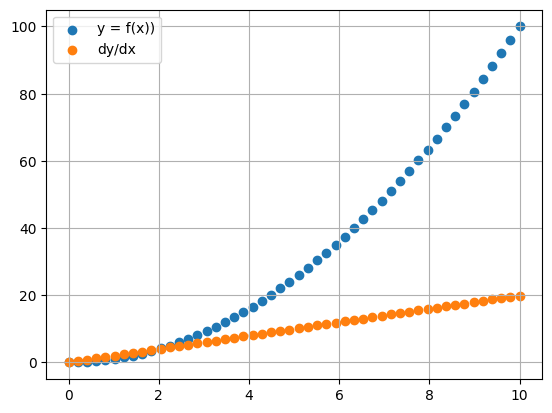

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 10, 50)
# y = np.sin(x)
y = x**2

# Approximate dy/dx using numpy gradient
dy_dx = np.gradient(y, x)

print(f"y: {y}")
print(f"dy_dx: {dy_dx}")

# plt.plot(x, y, label='y = sin(x)')
# plt.plot(x, dy_dx, label="dy/dx ~ cos(x)")
plt.scatter(x, y, label='y = f(x))')
plt.scatter(x, dy_dx, label="dy/dx")


plt.legend()
plt.grid(True)
plt.show()


## Assignment

Solve this new system and explain how you checked the result.

$$
\begin{aligned}
3x+2y&=16,\\
x-y&=2.
\end{aligned}
$$

1. Write the coefficient matrix $A$ and right-hand-side vector $\mathbf{b}$. Convert both to NumPy arrays.
2. Before solving, test the candidate $(4,1)$. Calculate the first dot product by hand, then calculate the full residual in NumPy. Explain what each residual entry says about its equation.
3. Find the solution with **np.linalg.solve**. Print the solution and its residual, then use **np.allclose** to check the residual against zero.
4. In one sentence, explain how the residual tells you whether the equations are satisfied.

**AI-assisted option.** Ask an AI assistant, “Help me write a short NumPy cell to solve this system using np.linalg.solve and check the residual. Explain how the rows of A match the equations.” Verify the matrix yourself and compare its result with your hand calculation for the candidate. Add your answers in new cells below.